#Algorithm Analysis and Implementation
# A Performance Comparison of Bubble Sort and Quick Sort

Algorithm Functionality

This activity examines two sorting algorithms, Bubble Sort and Quick Sort, implemented using Python. Both algorithms arrange numbers in ascending order, but their approaches differ. Bubble Sort compares adjacent elements and swaps them when necessary. This process continues until the list is sorted. Quick Sort selects a pivot, separates smaller and larger values, and recursively sorts the resulting groups.

Time Complexity and Efficiency

Bubble Sort has an average and worst-case time complexity of O(n²), making it relatively inefficient for large datasets. The implemented version also performs repeated comparisons on already sorted data. Quick Sort generally achieves O(n log n) time complexity, although its worst case is O(n²).

To evaluate performance, I tested both algorithms using randomly generated datasets containing 100, 300, 600, 1,000 and 1,500 elements. Each algorithm was timed five times per dataset, and the median execution time was recorded.

For 1,500 elements, Bubble Sort required approximately 0.145067 seconds, compared with 0.002898 seconds for Quick Sort. This made Quick Sort approximately 50 times faster in this experiment.

Comparison and Real-World Applications

The performance graph demonstrates that Bubble Sort’s execution time increases rapidly as dataset size grows, while Quick Sort remains considerably faster. For small datasets, both approaches can be practical, but Bubble Sort becomes increasingly inefficient as the amount of data increases.

Bubble Sort is useful in education because its comparison-and-swap process is straightforward to understand and implement. Quick Sort is more suitable for larger sorting tasks, including organising numerical records and preparing data for analysis, although its memory requirements and worst-case behaviour must also be considered.

Overall, this activity strengthened my understanding of how algorithm design influences computational efficiency and why selecting an appropriate algorithm matters in practical computing.

Size: 100 | Bubble Sort: 0.000463s | Quick Sort: 0.000124s
Size: 300 | Bubble Sort: 0.003463s | Quick Sort: 0.000393s
Size: 600 | Bubble Sort: 0.014304s | Quick Sort: 0.000811s
Size: 1000 | Bubble Sort: 0.043870s | Quick Sort: 0.001548s
Size: 1500 | Bubble Sort: 0.145067s | Quick Sort: 0.002898s


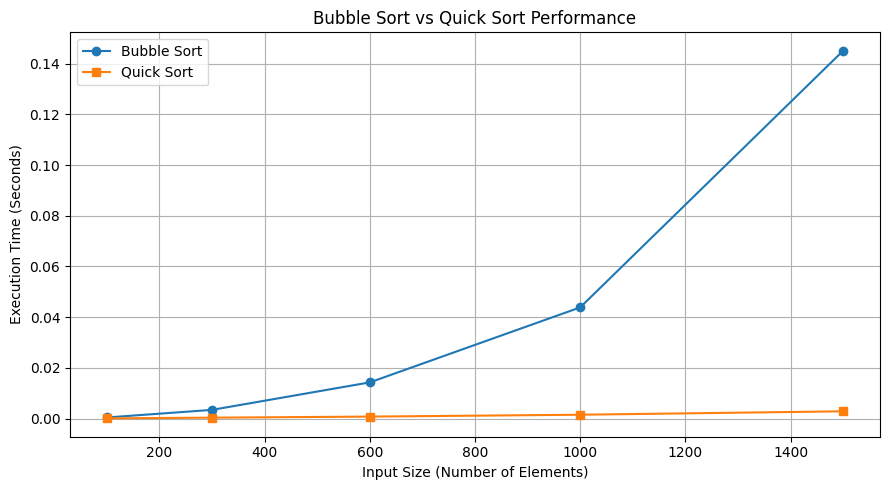

In [11]:
import random
import time
import statistics
import matplotlib.pyplot as plt

sizes = [100, 300, 600, 1000, 1500]
bubble_times = []
quick_times = []

random.seed(42)

for size in sizes:
  data = [random.randint(1, 10000) for _ in range(size)]
  bubble_results = []
  quick_results = []

  for _ in range(5):
      start = time.perf_counter()
      bubble_result = bubble_sort(data.copy())
      bubble_results.append(time.perf_counter() - start)

      start = time.perf_counter()
      quick_result = quick_sort(data.copy())
      quick_results.append(time.perf_counter() - start)

  assert bubble_result == quick_result == sorted(data)

  bubble_times.append(statistics.median(bubble_results))
  quick_times.append(statistics.median(quick_results))

  print(
      f"Size: {size} | "
      f"Bubble Sort: {bubble_times[-1]:.6f}s | "
      f"Quick Sort: {quick_times[-1]:.6f}s"
  )
plt.figure(figsize=(9, 5))
plt.plot(sizes, bubble_times, marker="o", label="Bubble Sort")
plt.plot(sizes, quick_times, marker="s", label="Quick Sort")

plt.title("Bubble Sort vs Quick Sort Performance")
plt.xlabel("Input Size (Number of Elements)")
plt.ylabel("Execution Time (Seconds)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("unit3_performance.png", dpi=300)
plt.show()

In [8]:
def quick_sort(arr):
    if len(arr) <= 1:
        return arr
    pivot = arr[len(arr) // 2]

    left = [x for x in arr if x < pivot]
    middle = [x for x in arr if x == pivot]
    right = [x for x in arr if x > pivot]

    return quick_sort(left) + middle + quick_sort(right)


numbers = [5, 2, 9, 1, 7]

print("Quick Sort result:", quick_sort(numbers.copy()))

Quick Sort result: [1, 2, 5, 7, 9]


In [5]:
def bubble_sort(arr):
    n = len(arr)
    for i in range(n):
        for j in range(n - i - 1):
            if arr[j] > arr[j + 1]:
                arr[j], arr[j + 1] = arr[j + 1], arr[j]
    return arr

numbers = [5, 2, 9, 1, 7]
print("Bubble Sort result:", bubble_sort(numbers.copy()))

Bubble Sort result: [1, 2, 5, 7, 9]
